In [18]:
# importing dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [19]:
df = pd.read_csv('/content/Electric_Vehicle_Population_Data.csv')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30829 entries, 0 to 30828
Data columns (total 17 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   VIN (1-10)                                         30829 non-null  object 
 1   County                                             30829 non-null  object 
 2   City                                               30829 non-null  object 
 3   State                                              30829 non-null  object 
 4   Postal Code                                        30829 non-null  int64  
 5   Model Year                                         30829 non-null  int64  
 6   Make                                               30829 non-null  object 
 7   Model                                              30793 non-null  object 
 8   Electric Vehicle Type                              30829 non-null  object 
 9   Clean 

In [21]:
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EB4L,Yakima,Yakima,WA,98908,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,322.0,0.0,14.0,127175366.0,POINT (-120.56916 46.58514),PACIFICORP,5.307700e+10
1,5YJ3E1EA7K,San Diego,San Diego,CA,92101,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,0.0,NaN,266614659.0,POINT (-117.16171 32.71568),NaN,6.073005e+09
2,7JRBR0FL9M,Lane,Eugene,OR,97404,2021,VOLVO,S60,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,22.0,0.0,NaN,144502018.0,POINT (-123.12802 44.09573),NaN,4.103900e+10
3,5YJXCBE21K,Yakima,Yakima,WA,98908,2019,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,289.0,0.0,14.0,477039944.0,POINT (-120.56916 46.58514),PACIFICORP,5.307700e+10
4,5UXKT0C5XH,Snohomish,Bothell,WA,98021,2017,BMW,X5,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,14.0,0.0,1.0,106314946.0,POINT (-122.18384 47.8031),PUGET SOUND ENERGY INC,5.306105e+10


In [22]:
df.isnull().sum()

,0
VIN (1-10),0
County,0
City,0
State,0
Postal Code,0
Model Year,0
Make,0
Model,36
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [23]:
# For treating the missing value
# check the dtype if it is obj use mode or int use mean/median
for col in df.columns:
  if df[col].dtype == 'object':
    df[col] = df[col].fillna(df[col].mode()[0])
  else:
    df[col] = df[col].fillna(df[col].median())


In [24]:
df.isnull().sum()

,0
VIN (1-10),0
County,0
City,0
State,0
Postal Code,0
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


In [25]:
df.duplicated().sum()

np.int64(0)

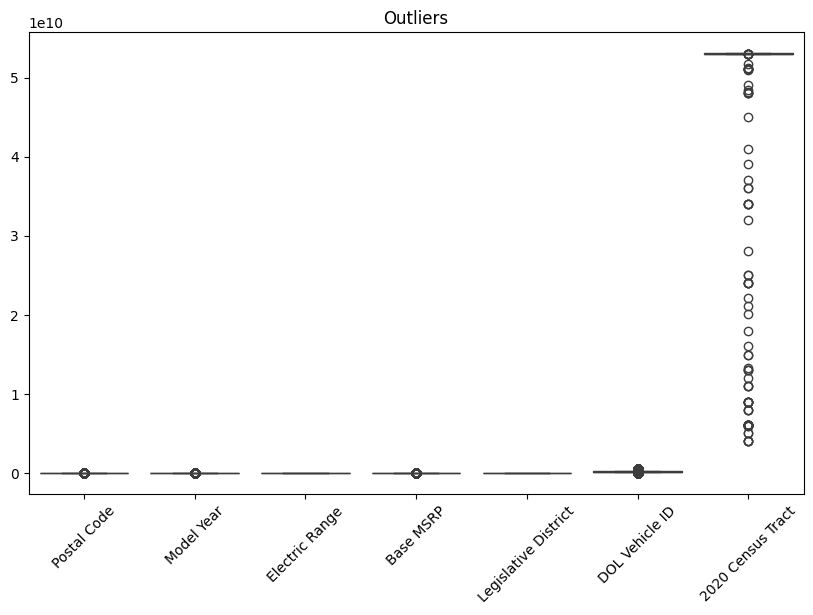

In [26]:
# Outliers
plt.figure(figsize=(10,6))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.title('Outliers')
plt.show()

In [27]:
# meaningful information
num_col = [
    'Model Year',
    'Electric Range',
    'Base MSRP'
]

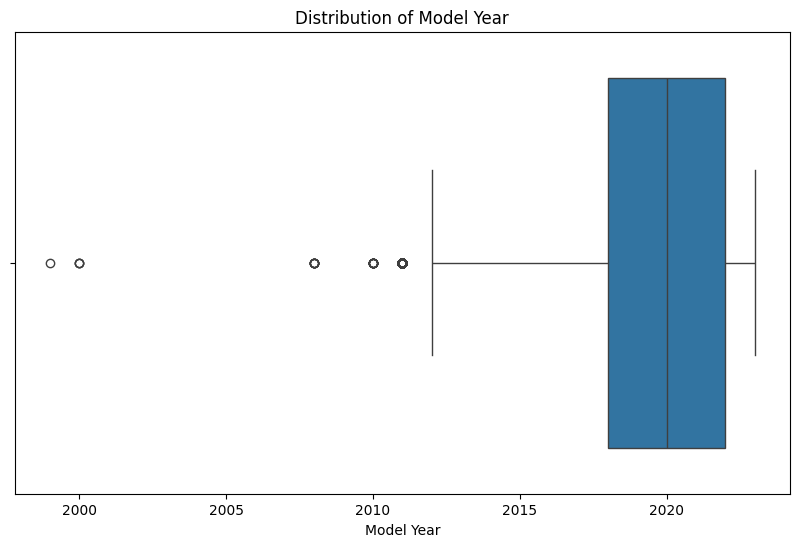

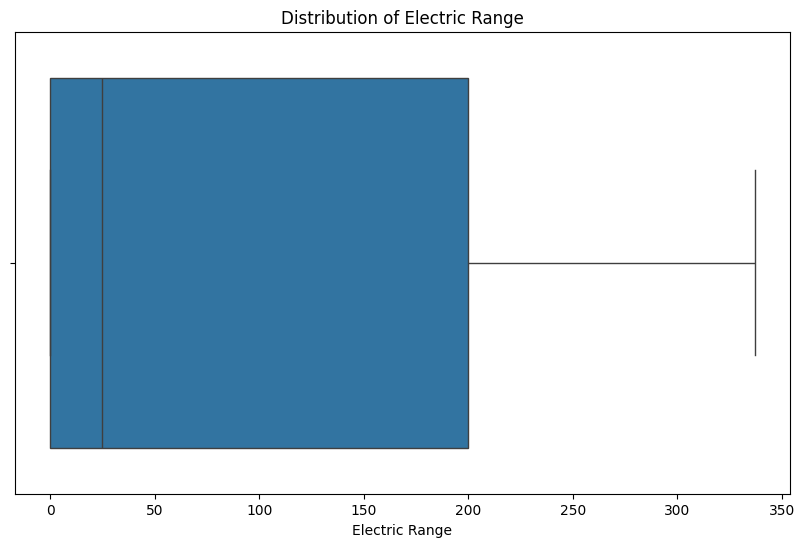

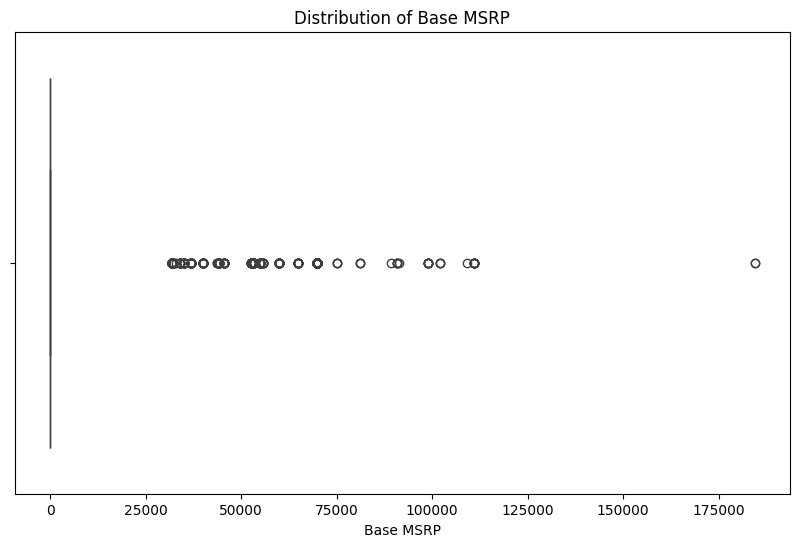

In [28]:
for col in num_col:
  plt.figure(figsize=(10,6))
  sns.boxplot(x=df[col])
  plt.title(f'Distribution of {col}')
  plt.show()

In [29]:
for col in ['Model Year', 'Base MSRP']:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - (1.5 * iqr)
  upper_bound = q3 + (1.5 * iqr)
  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]


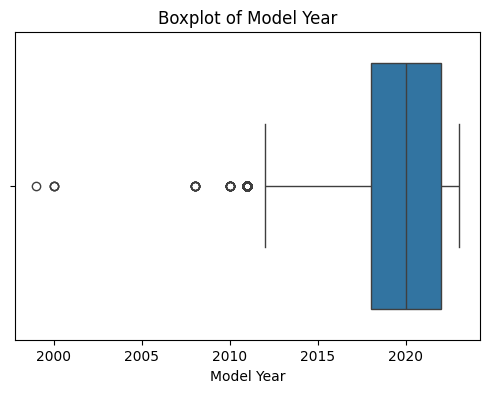

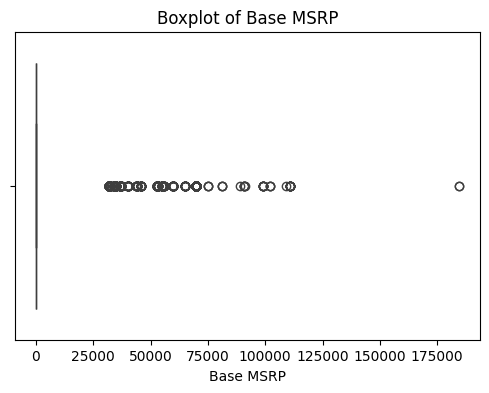

In [30]:
for col in ['Model Year', 'Base MSRP']:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30829 entries, 0 to 30828
Data columns (total 17 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   VIN (1-10)                                         30829 non-null  object 
 1   County                                             30829 non-null  object 
 2   City                                               30829 non-null  object 
 3   State                                              30829 non-null  object 
 4   Postal Code                                        30829 non-null  int64  
 5   Model Year                                         30829 non-null  int64  
 6   Make                                               30829 non-null  object 
 7   Model                                              30829 non-null  object 
 8   Electric Vehicle Type                              30829 non-null  object 
 9   Clean 

In [31]:
df.describe()

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,30829.000000,30829.000000,30829.000000,30829.000000,30829.000000,3.082900e+04,3.082900e+04
mean,98136.387168,2019.376010,79.555256,1581.094424,29.915794,2.041634e+08,5.294829e+10
std,2903.450169,2.995332,100.130211,9864.661174,14.704634,8.947137e+07,1.934677e+09
min,1731.000000,1999.000000,0.000000,0.000000,1.000000,1.073400e+04,4.013061e+09
25%,98052.000000,2018.000000,0.000000,0.000000,18.000000,1.539041e+08,5.303301e+10
50%,98119.000000,2020.000000,25.000000,0.000000,34.000000,1.998787e+08,5.303303e+10
75%,98368.000000,2022.000000,200.000000,0.000000,43.000000,2.280118e+08,5.305307e+10
max,99403.000000,2023.000000,337.000000,184400.000000,49.000000,4.789355e+08,5.307794e+10


In [33]:
df.describe(include='object')

,VIN (1-10),County,City,State,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Vehicle Location,Electric Utility
count,30829,30829,30829,30829,30829,30829,30829,30829,30829,30829
unique,5690,90,430,28,33,113,2,4,524,66
top,5YJYGDEE0M,King,Seattle,WA,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,POINT (-122.13158 47.67858),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
freq,125,16533,5678,30743,14062,5988,23848,14655,827,11269


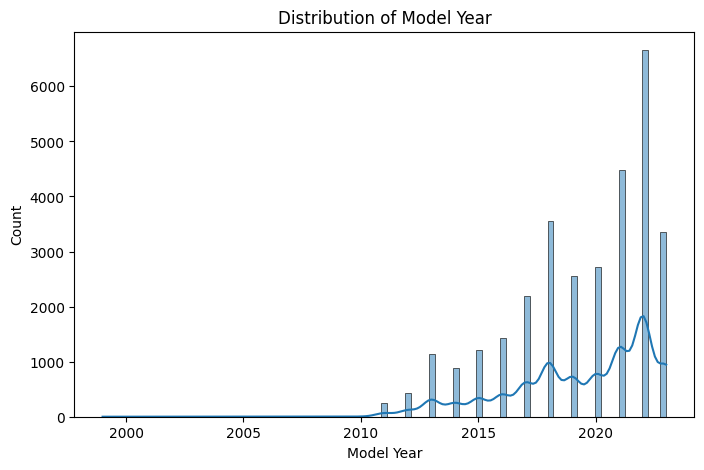

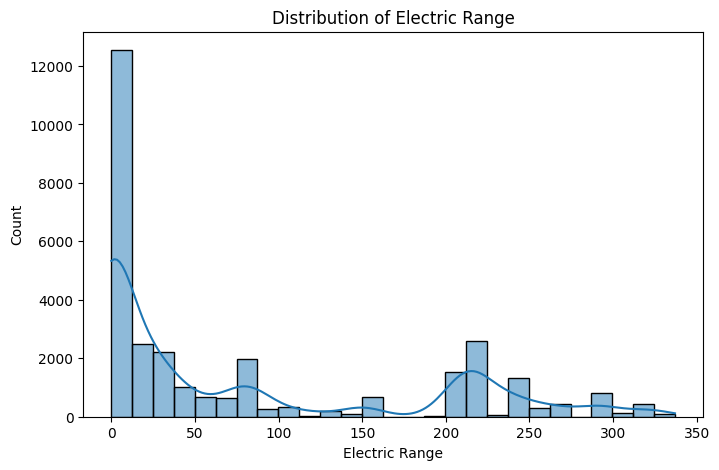

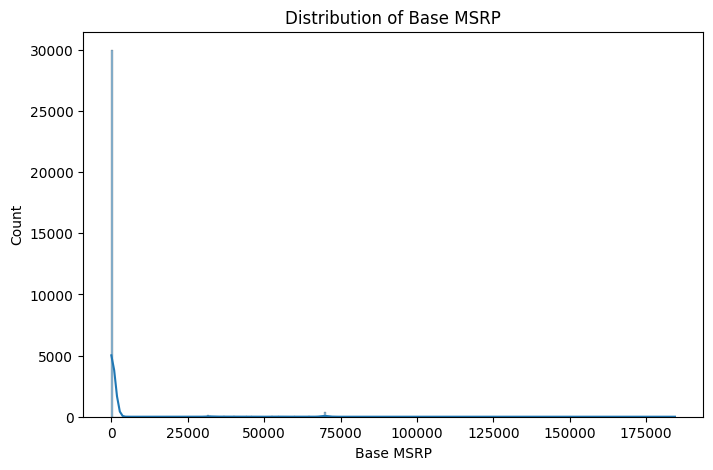

In [34]:
num_cols = ['Model Year', 'Electric Range', 'Base MSRP']

for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

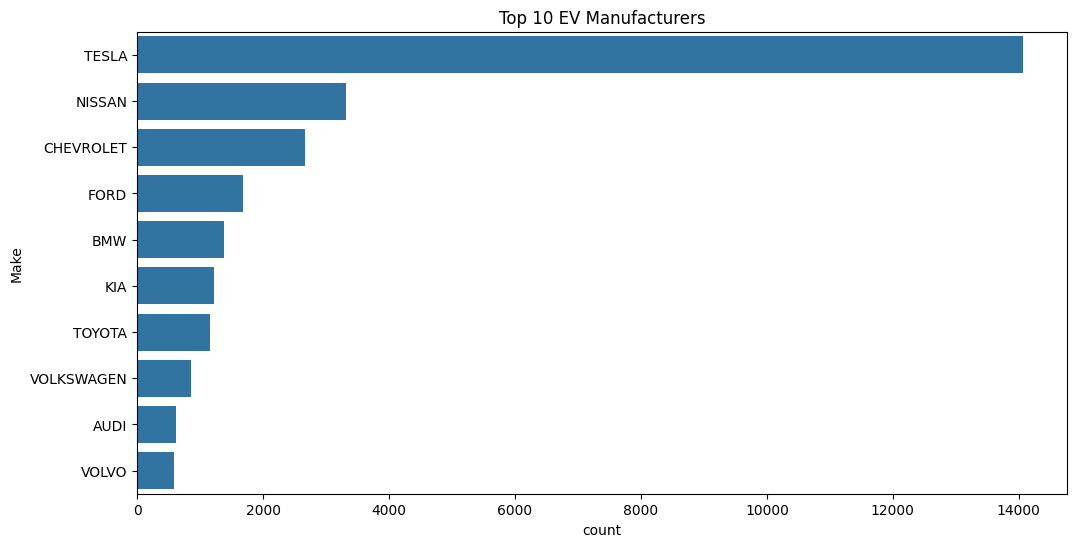

In [35]:
plt.figure(figsize=(12,6))

sns.countplot(
    y='Make',
    data=df,
    order=df['Make'].value_counts().head(10).index
)

plt.title('Top 10 EV Manufacturers')
plt.show()

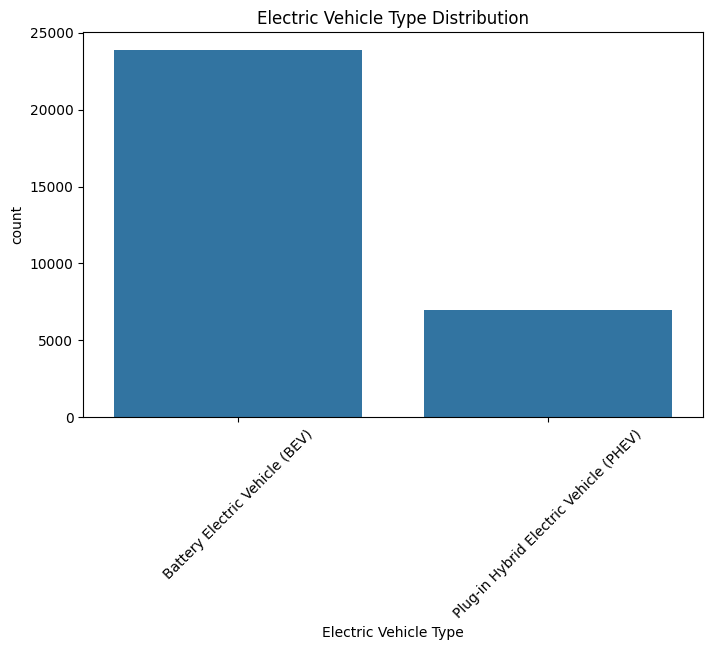

In [36]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Electric Vehicle Type',
    data=df
)

plt.xticks(rotation=45)
plt.title('Electric Vehicle Type Distribution')
plt.show()

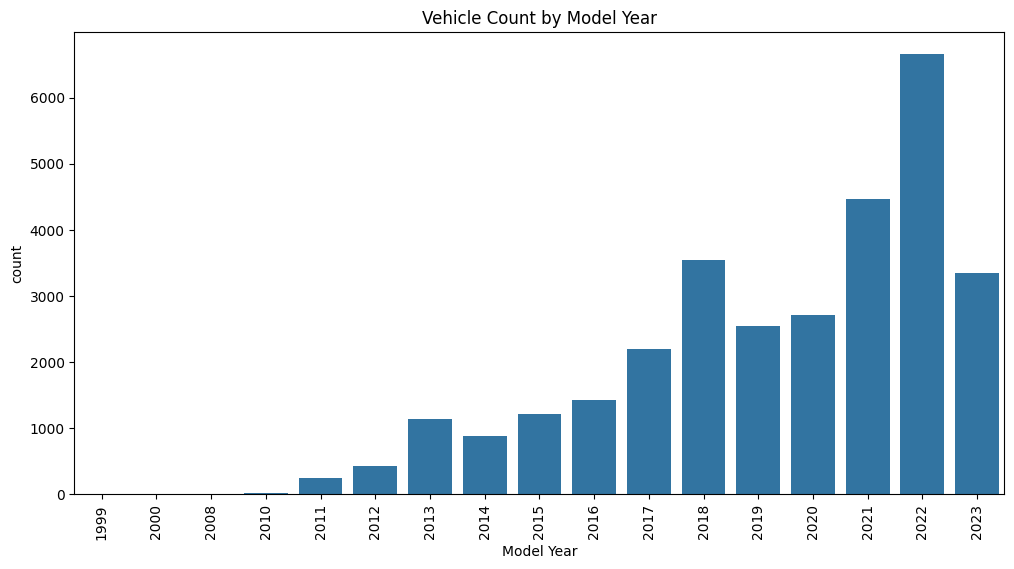

In [37]:
plt.figure(figsize=(12,6))

sns.countplot(
    x='Model Year',
    data=df
)

plt.xticks(rotation=90)
plt.title('Vehicle Count by Model Year')
plt.show()

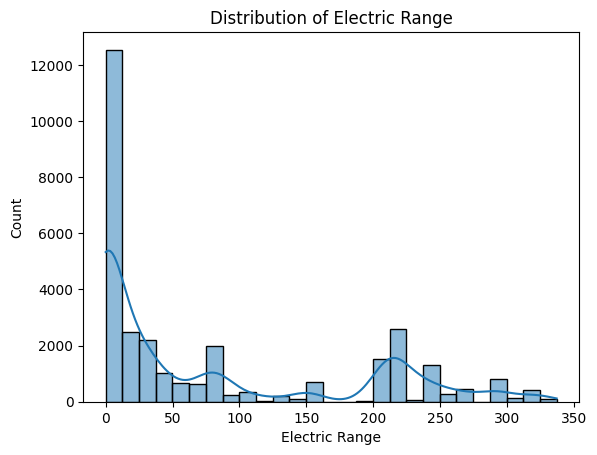

In [41]:
# Univariate analysis
sns.histplot(df['Electric Range'], kde=True)
plt.title('Distribution of Electric Range')
plt.show()

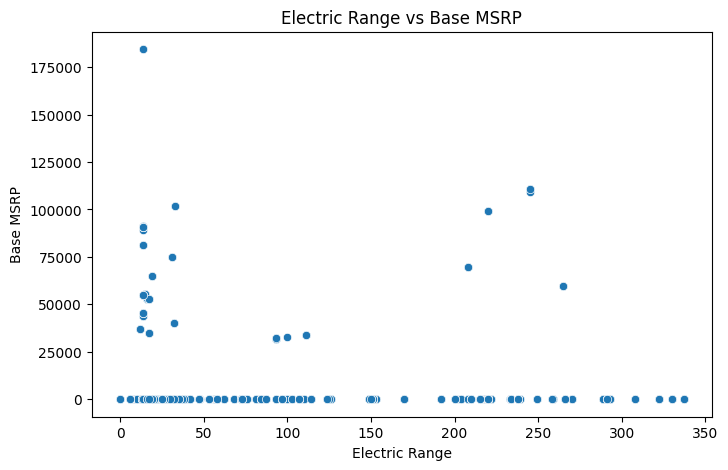

In [42]:
# Bivaraite analysis
plt.figure(figsize=(8,5))
sns.scatterplot(
    x='Electric Range',
    y='Base MSRP',
    data=df
)
plt.title('Electric Range vs Base MSRP')
plt.show()

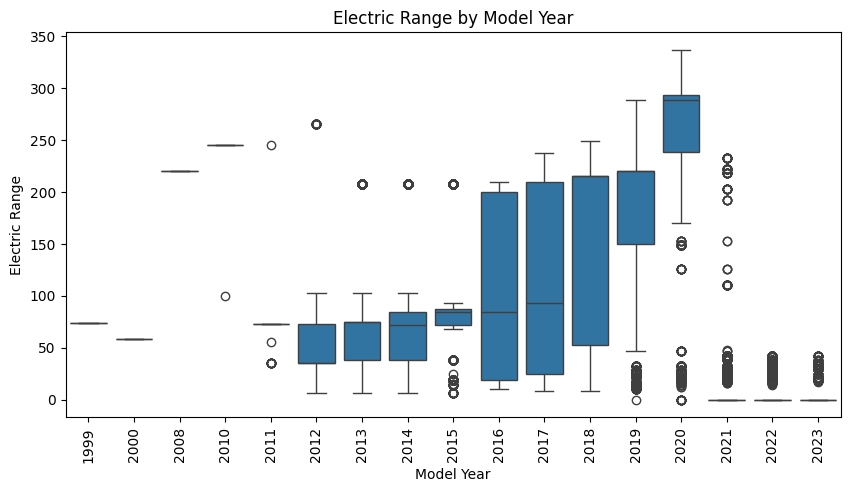

In [43]:
plt.figure(figsize=(10,5))
sns.boxplot(
    x='Model Year',
    y='Electric Range',
    data=df
)
plt.xticks(rotation=90)
plt.title('Electric Range by Model Year')
plt.show()

In [62]:
df.drop([
    'DOL Vehicle ID',
    '2020 Census Tract'
], axis=1, inplace=True)

In [63]:
# recheck
print(df.columns)

Index(['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year',
       'Make', 'Model', 'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range',
       'Base MSRP', 'Legislative District', 'Vehicle Location',
       'Electric Utility'],
      dtype='object')


In [65]:
# changing obj dtype into num dtype
df.select_dtypes(include='object').columns

Index(['VIN (1-10)', 'County', 'City', 'State', 'Make', 'Model',
       'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Vehicle Location',
       'Electric Utility'],
      dtype='object')

In [66]:
df = pd.get_dummies(df, drop_first=True)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29974 entries, 0 to 30828
Columns: 6634 entries, Postal Code to Electric Utility_PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY
dtypes: bool(6629), float64(3), int64(2)
memory usage: 190.9 MB


In [68]:
print(df.dtypes)

Postal Code                                                              int64
Model Year                                                               int64
Electric Range                                                         float64
Base MSRP                                                              float64
Legislative District                                                   float64
                                                                        ...   
Electric Utility_PUD NO 1 OF WHATCOM COUNTY                               bool
Electric Utility_PUD NO 2 OF GRANT COUNTY                                 bool
Electric Utility_PUGET SOUND ENERGY INC                                   bool
Electric Utility_PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)            bool
Electric Utility_PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY       bool
Length: 6634, dtype: object


In [69]:
df.select_dtypes(include='object')

""
0
1
2
3
4
...
30824
30825
30826
30827


In [70]:
print(df.columns)

Index(['Postal Code', 'Model Year', 'Electric Range', 'Base MSRP',
       'Legislative District', 'VIN (1-10)_1C4JJXN61P',
       'VIN (1-10)_1C4JJXN62P', 'VIN (1-10)_1C4JJXN63P',
       'VIN (1-10)_1C4JJXN64P', 'VIN (1-10)_1C4JJXN65P',
       ...
       'Electric Utility_PORTLAND GENERAL ELECTRIC CO',
       'Electric Utility_PUD NO 1 OF CHELAN COUNTY',
       'Electric Utility_PUD NO 1 OF DOUGLAS COUNTY',
       'Electric Utility_PUD NO 1 OF OKANOGAN COUNTY',
       'Electric Utility_PUD NO 1 OF PEND OREILLE COUNTY',
       'Electric Utility_PUD NO 1 OF WHATCOM COUNTY',
       'Electric Utility_PUD NO 2 OF GRANT COUNTY',
       'Electric Utility_PUGET SOUND ENERGY INC',
       'Electric Utility_PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)',
       'Electric Utility_PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY'],
      dtype='object', length=6634)


In [73]:
print(df.columns.tolist())

['Postal Code', 'Model Year', 'Electric Range', 'Base MSRP', 'Legislative District', 'VIN (1-10)_1C4JJXN61P', 'VIN (1-10)_1C4JJXN62P', 'VIN (1-10)_1C4JJXN63P', 'VIN (1-10)_1C4JJXN64P', 'VIN (1-10)_1C4JJXN65P', 'VIN (1-10)_1C4JJXN66P', 'VIN (1-10)_1C4JJXN67P', 'VIN (1-10)_1C4JJXN68P', 'VIN (1-10)_1C4JJXN69P', 'VIN (1-10)_1C4JJXN6XP', 'VIN (1-10)_1C4JJXP60M', 'VIN (1-10)_1C4JJXP60N', 'VIN (1-10)_1C4JJXP60P', 'VIN (1-10)_1C4JJXP61M', 'VIN (1-10)_1C4JJXP61N', 'VIN (1-10)_1C4JJXP61P', 'VIN (1-10)_1C4JJXP62M', 'VIN (1-10)_1C4JJXP62N', 'VIN (1-10)_1C4JJXP62P', 'VIN (1-10)_1C4JJXP63M', 'VIN (1-10)_1C4JJXP63N', 'VIN (1-10)_1C4JJXP63P', 'VIN (1-10)_1C4JJXP64M', 'VIN (1-10)_1C4JJXP64N', 'VIN (1-10)_1C4JJXP64P', 'VIN (1-10)_1C4JJXP65M', 'VIN (1-10)_1C4JJXP65N', 'VIN (1-10)_1C4JJXP65P', 'VIN (1-10)_1C4JJXP66M', 'VIN (1-10)_1C4JJXP66N', 'VIN (1-10)_1C4JJXP66P', 'VIN (1-10)_1C4JJXP67M', 'VIN (1-10)_1C4JJXP67N', 'VIN (1-10)_1C4JJXP67P', 'VIN (1-10)_1C4JJXP68M', 'VIN (1-10)_1C4JJXP68N', 'VIN (1-10)_1C4

In [74]:
# Choose target
y = df['Electric Range']   # example

# Features
X = df.drop('Electric Range', axis=1)

# Train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [45]:
Q1 = df['Base MSRP'].quantile(0.25)
Q3 = df['Base MSRP'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['Base MSRP'] >= lower) & (df['Base MSRP'] <= upper)]

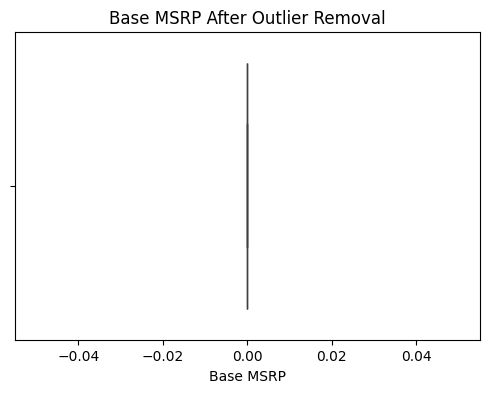

In [50]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['Base MSRP'])
plt.title('Base MSRP After Outlier Removal')
plt.show()

In [51]:
df['Base MSRP'].describe()

,Base MSRP
count,29974.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


In [52]:
df['Base MSRP'].value_counts().head(10)

,count
Base MSRP,
0.0,29974


In [53]:
print(df.shape)

(29974, 17)


In [60]:
print("Unique values:", df['Base MSRP'].nunique())
print("Min:", df['Base MSRP'].min())
print("Max:", df['Base MSRP'].max())

Unique values: 1
Min: 0.0
Max: 0.0


<Axes: >

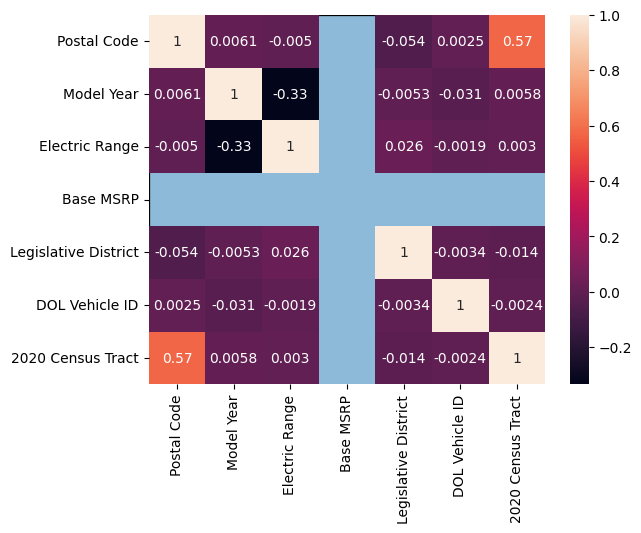

In [61]:
# Univariate
sns.histplot(df['Electric Range'], kde=True)

# Bivariate
sns.scatterplot(x='Electric Range',
                y='Base MSRP',
                data=df)

# Multivariate
sns.heatmap(df.corr(numeric_only=True),
            annot=True)

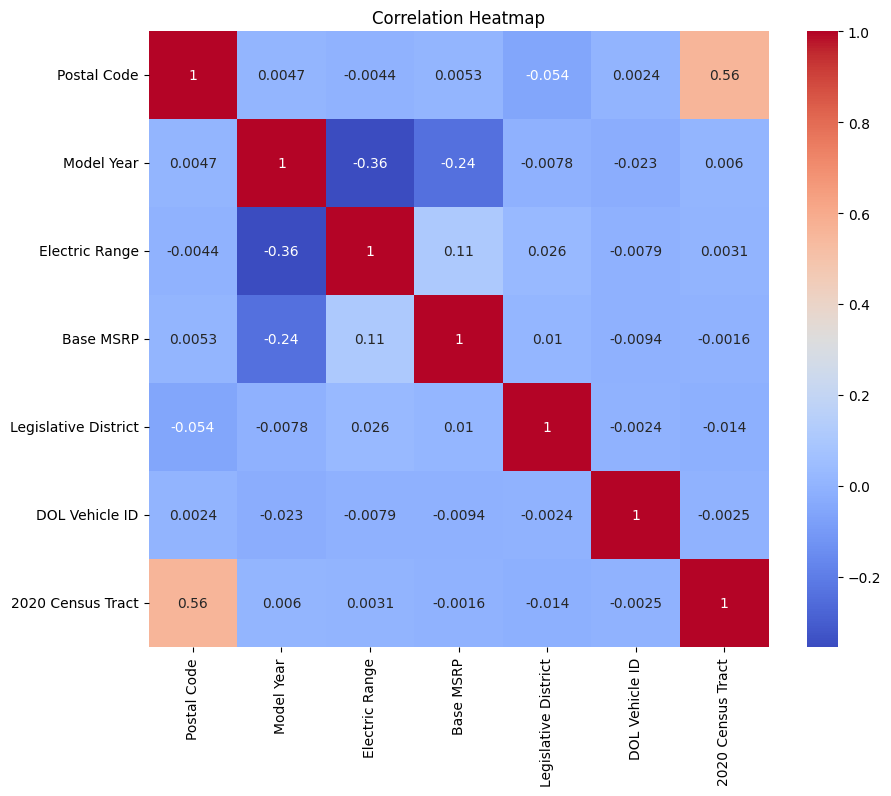

In [38]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()